# Kathmandu US AQI: Modelling and Evaluation
Group E "Los Lobos" | CSC61304 | Track 10: Air Quality Monitoring

Runs after `kathmandu_preprocessing.ipynb`. It reads `kathmandu_train.csv` and `kathmandu_test.csv`.

**Question for the report:** how much of Kathmandu's hourly US AQI can weather and time of year explain?

**Plan**
1. Load the split and keep only the 8 chosen inputs (no `time`)
2. Baselines: what do we get with no weather at all?
3. Models: linear regression, random forest, gradient boosting
4. Tune with time-ordered validation inside the training years
5. Evaluate once on the test year: overall, by season, by AQI band, and bias
6. Feature importance, then save results

Defaults I chose where no decision was recorded yet (change them freely): StandardScaler for the linear model only, MAE / RMSE / R2 as metrics, small tuning grids, random_state 42.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

DATA_DIR = Path('.')
OUT_DIR = DATA_DIR
SEED = 42
TARGET = 'us_aqi'
FEATURES = ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation',
            'month_sin', 'month_cos', 'hour_sin', 'hour_cos']

train = pd.read_csv(DATA_DIR / 'kathmandu_train.csv', parse_dates=['time'])
test = pd.read_csv(DATA_DIR / 'kathmandu_test.csv', parse_dates=['time'])

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

assert 'time' not in X_train.columns, 'time must not reach the model'
assert train['time'].max() < test['time'].min()
print('train:', X_train.shape, '| test:', X_test.shape)
print('features:', FEATURES)

train: (26304, 8) | test: (8760, 8)
features: ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']


## 1. Scaling decision
- **Trees (random forest, gradient boosting):** only ask "is this value above a threshold?", so scaling changes nothing. They get the raw columns.
- **Linear regression:** the size of a coefficient depends on the unit of its column, so we standardise (mean 0, spread 1). The scaler is fitted on the **training rows only**, then reused on test. Fitting it on test too would let test information leak into training.
- The target is never scaled.
- The group's distance-based or neural models would use the same scaler idea, so the scaled version below is what they can reuse.

In [2]:
scaler = StandardScaler().fit(X_train)
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
Xs_test = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

print('train means (should be about 0):', Xs_train.mean().round(3).to_dict())
print('train stds  (should be about 1):', Xs_train.std().round(3).to_dict())
print('test means  (close, not exactly 0):', Xs_test.mean().round(2).to_dict())
joblib.dump(scaler, OUT_DIR / 'scaler.joblib')

train means (should be about 0): {'temperature_2m': 0.0, 'dew_point_2m': -0.0, 'cloud_cover': -0.0, 'precipitation': 0.0, 'month_sin': -0.0, 'month_cos': 0.0, 'hour_sin': -0.0, 'hour_cos': 0.0}
train stds  (should be about 1): {'temperature_2m': 1.0, 'dew_point_2m': 1.0, 'cloud_cover': 1.0, 'precipitation': 1.0, 'month_sin': 1.0, 'month_cos': 1.0, 'hour_sin': 1.0, 'hour_cos': 1.0}
test means  (close, not exactly 0): {'temperature_2m': -0.02, 'dew_point_2m': 0.16, 'cloud_cover': 0.09, 'precipitation': 0.05, 'month_sin': -0.0, 'month_cos': -0.0, 'hour_sin': -0.0, 'hour_cos': 0.0}


['scaler.joblib']

## 2. Metrics
- **MAE** (mean absolute error): the typical miss, in AQI points. Easiest to explain.
- **RMSE**: like MAE but punishes big misses harder, which matters for the dangerous spikes.
- **R2**: share of the variation in AQI that the model explains. 0 means no better than always guessing the training mean, 1 is perfect, and it can go negative.
- **Band accuracy**: share of hours where the predicted AQI lands in the same US AQI band (Good, Moderate, ...) as the real one. This is the number a health warning actually cares about.

In [3]:
BINS = [-np.inf, 50, 100, 150, 200, 300, np.inf]
BAND_LABELS = ['Good', 'Moderate', 'Sensitive', 'Unhealthy', 'Very unhealthy', 'Hazardous']

def band(values):
    return pd.cut(pd.Series(np.asarray(values)), bins=BINS, labels=BAND_LABELS)

def scores(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'R2': r2_score(y_true, y_pred),
        'Bias (pred - actual)': float(np.mean(y_pred - y_true)),
        'Band accuracy %': float((band(y_true).values == band(y_pred).values).mean() * 100),
    }

results = {}     # model name -> test scores
test_pred = {}   # model name -> test predictions

## 3. Baselines (no weather)
A model only proves something if it beats a simple rule. Three rules, all learned from the **training years only**:
1. always predict the training mean
2. predict the training mean for that **month**
3. predict the training mean for that **month and hour**

If the weather model cannot beat rule 3, weather adds nothing beyond the calendar.

In [4]:
# 3.1 global mean
pred = np.full(len(test), y_train.mean())
results['Baseline: overall mean'] = scores(y_test, pred); test_pred['Baseline: overall mean'] = pred

# 3.2 mean by month
month_mean = train.groupby('month')[TARGET].mean()
pred = test['month'].map(month_mean).values
results['Baseline: mean by month'] = scores(y_test, pred); test_pred['Baseline: mean by month'] = pred

# 3.3 mean by month and hour
mh_mean = train.groupby(['month', 'hour'])[TARGET].mean()
pred = pd.Series(list(zip(test['month'], test['hour']))).map(mh_mean).values
results['Baseline: mean by month+hour'] = scores(y_test, pred); test_pred['Baseline: mean by month+hour'] = pred

pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2,Bias (pred - actual),Band accuracy %
Baseline: overall mean,34.084,39.926,-0.120,-13.089,26.438
Baseline: mean by month,22.080,27.800,0.457,-13.110,56.427
Baseline: mean by month+hour,21.635,27.445,0.471,-13.110,55.902


## 4. Time-ordered validation (used for tuning)
Tuning needs a score to compare settings, but the test year must stay untouched. So the **training years** are split into folds that respect time:

| Fold | Fit on | Validate on |
|---|---|---|
| 1 | Oct 2022 - Sep 2023 | Oct 2023 - Sep 2024 |
| 2 | Oct 2022 - Sep 2024 | Oct 2024 - Sep 2025 |

Shuffled folds would put neighbouring hours on both sides and reward memorising. The validation score is the mean RMSE over the two folds.

In [5]:
train_idx = train.reset_index(drop=True)
y1_end = pd.Timestamp('2023-10-01'); y2_end = pd.Timestamp('2024-10-01'); y3_end = pd.Timestamp('2025-10-01')
FOLDS = [
    (train_idx.index[train_idx['time'] < y1_end],  train_idx.index[(train_idx['time'] >= y1_end) & (train_idx['time'] < y2_end)]),
    (train_idx.index[train_idx['time'] < y2_end],  train_idx.index[(train_idx['time'] >= y2_end) & (train_idx['time'] < y3_end)]),
]
for i, (tr, va) in enumerate(FOLDS, 1):
    print(f'fold {i}: fit on {len(tr)} rows, validate on {len(va)} rows')

def cv_rmse(make_model, use_scaled=False):
    X = Xs_train if use_scaled else X_train
    rmses = []
    for tr, va in FOLDS:
        m = make_model()
        m.fit(X.iloc[tr], y_train.iloc[tr])
        rmses.append(np.sqrt(mean_squared_error(y_train.iloc[va], m.predict(X.iloc[va]))))
    return float(np.mean(rmses)), rmses

fold 1: fit on 8760 rows, validate on 8784 rows
fold 2: fit on 17544 rows, validate on 8760 rows


## 5. Linear regression
No settings worth tuning. It draws the best straight-line combination of the inputs, so it cannot bend. Useful as the "simple model" to compare the trees against.

In [6]:
lin = LinearRegression().fit(Xs_train, y_train)
pred = lin.predict(Xs_test)
results['Linear regression'] = scores(y_test, pred); test_pred['Linear regression'] = pred
print('validation RMSE (mean of folds):', round(cv_rmse(LinearRegression, use_scaled=True)[0], 2))
print(pd.Series(lin.coef_, index=FEATURES).round(2).to_string())
joblib.dump(lin, OUT_DIR / 'model_linear.joblib')

validation RMSE (mean of folds): 34.58
temperature_2m    -4.91
dew_point_2m       2.76
cloud_cover       -3.02
precipitation     -2.07
month_sin         14.89
month_cos          9.66
hour_sin          -3.67
hour_cos          -2.82


['model_linear.joblib']

## 6. Random forest: tuning
Settings searched (small grid, so it runs in minutes):
- `max_depth`: how deep each tree may grow. Deep trees fit the training years closely, shallow ones generalise more.
- `min_samples_leaf`: smallest group of hours allowed in a leaf. Bigger means smoother, less noise-fitting predictions.
- `max_features`: share of inputs each split may look at. Lower makes the trees more different from each other.

In [7]:
rf_grid = list(ParameterGrid({
    'max_depth': [6, 12, None],
    'min_samples_leaf': [5, 25, 100],
    'max_features': [0.5, 1.0],
}))
rf_rows = []
for p in rf_grid:
    mk = lambda p=p: RandomForestRegressor(n_estimators=120, random_state=SEED, n_jobs=-1, **p)
    mean_rmse, per_fold = cv_rmse(mk)
    rf_rows.append({**p, 'cv_rmse': mean_rmse, 'fold1': per_fold[0], 'fold2': per_fold[1]})
rf_cv = pd.DataFrame(rf_rows).sort_values('cv_rmse').reset_index(drop=True)
rf_cv.round(2).head(8)

,max_depth,max_features,min_samples_leaf,cv_rmse,fold1,fold2
0,12.0,0.5,25,33.28,31.15,35.40
1,NaN,0.5,25,33.31,31.14,35.49
2,12.0,0.5,100,33.32,31.36,35.29
3,NaN,0.5,100,33.33,31.36,35.30
4,6.0,0.5,25,33.38,31.21,35.55
5,6.0,0.5,5,33.39,31.22,35.56
6,6.0,0.5,100,33.41,31.38,35.43
7,12.0,1.0,25,33.53,31.46,35.60


In [8]:
best_rf_params = {k: rf_cv.loc[0, k] for k in ['max_depth', 'min_samples_leaf', 'max_features']}
best_rf_params['max_features'] = float(best_rf_params['max_features'])
best_rf_params['max_depth'] = None if pd.isna(best_rf_params['max_depth']) else int(best_rf_params['max_depth'])
best_rf_params['min_samples_leaf'] = int(best_rf_params['min_samples_leaf'])
print('best random forest settings:', best_rf_params, '| validation RMSE:', round(rf_cv.loc[0, 'cv_rmse'], 2))
rf_cv.to_csv(OUT_DIR / 'tuning_random_forest.csv', index=False)

best random forest settings: {'max_depth': 12, 'min_samples_leaf': 25, 'max_features': 0.5} | validation RMSE: 33.28


## 7. Gradient boosting: tuning
Builds many small trees one after another, each fixing the mistakes of the ones before. Settings: `learning_rate` (size of each correction), `max_depth` (size of each small tree), `min_samples_leaf` (smoothness).

In [9]:
gb_grid = list(ParameterGrid({
    'learning_rate': [0.03, 0.1],
    'max_depth': [3, 6],
    'min_samples_leaf': [50, 200],
}))
gb_rows = []
for p in gb_grid:
    mk = lambda p=p: HistGradientBoostingRegressor(max_iter=250, random_state=SEED, **p)
    mean_rmse, per_fold = cv_rmse(mk)
    gb_rows.append({**p, 'cv_rmse': mean_rmse, 'fold1': per_fold[0], 'fold2': per_fold[1]})
gb_cv = pd.DataFrame(gb_rows).sort_values('cv_rmse').reset_index(drop=True)
best_gb_params = {k: gb_cv.loc[0, k] for k in ['learning_rate', 'max_depth', 'min_samples_leaf']}
best_gb_params['learning_rate'] = float(best_gb_params['learning_rate'])
best_gb_params['max_depth'] = int(best_gb_params['max_depth']); best_gb_params['min_samples_leaf'] = int(best_gb_params['min_samples_leaf'])
print('best gradient boosting settings:', best_gb_params, '| validation RMSE:', round(gb_cv.loc[0, 'cv_rmse'], 2))
gb_cv.to_csv(OUT_DIR / 'tuning_gradient_boosting.csv', index=False)
gb_cv.round(2)

best gradient boosting settings: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 200} | validation RMSE: 33.17


,learning_rate,max_depth,min_samples_leaf,cv_rmse,fold1,fold2
0,0.10,3,200,33.17,31.44,34.91
1,0.03,6,50,33.18,31.18,35.17
2,0.03,6,200,33.25,31.41,35.09
3,0.10,3,50,33.30,31.40,35.20
4,0.03,3,200,33.34,31.36,35.32
5,0.03,3,50,33.40,31.31,35.49
6,0.10,6,50,33.41,31.56,35.27
7,0.10,6,200,33.53,31.67,35.38


## 8. Fit the final models on all training years, then test once
The test year was not used for any choice above. Each model is refitted on all three training years with its best settings, then scored on the test year a single time.

In [10]:
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **best_rf_params).fit(X_train, y_train)
pred = rf.predict(X_test)
results['Random forest (tuned)'] = scores(y_test, pred); test_pred['Random forest (tuned)'] = pred

gb = HistGradientBoostingRegressor(max_iter=250, random_state=SEED, **best_gb_params).fit(X_train, y_train)
pred = gb.predict(X_test)
results['Gradient boosting (tuned)'] = scores(y_test, pred); test_pred['Gradient boosting (tuned)'] = pred

joblib.dump(rf, OUT_DIR / 'model_random_forest.joblib')
joblib.dump(gb, OUT_DIR / 'model_gradient_boosting.joblib')

comparison = pd.DataFrame(results).T
comparison.round(3)

,MAE,RMSE,R2,Bias (pred - actual),Band accuracy %
Baseline: overall mean,34.084,39.926,-0.120,-13.089,26.438
Baseline: mean by month,22.080,27.800,0.457,-13.110,56.427
Baseline: mean by month+hour,21.635,27.445,0.471,-13.110,55.902
Linear regression,22.754,28.181,0.442,-12.983,53.881
Random forest (tuned),20.123,25.295,0.550,-10.775,57.660
Gradient boosting (tuned),19.870,25.001,0.561,-10.681,57.511


In [11]:
# training-year fit versus test-year fit: a big gap means overfitting
rows = {}
for name, model, Xtr in [('Linear regression', lin, Xs_train), ('Random forest (tuned)', rf, X_train), ('Gradient boosting (tuned)', gb, X_train)]:
    s_tr = scores(y_train, model.predict(Xtr))
    rows[name] = {'train R2': s_tr['R2'], 'test R2': results[name]['R2'], 'train MAE': s_tr['MAE'], 'test MAE': results[name]['MAE']}
pd.DataFrame(rows).T.round(3)

,train R2,test R2,train MAE,test MAE
Linear regression,0.353,0.442,23.190,22.754
Random forest (tuned),0.608,0.550,17.498,20.123
Gradient boosting (tuned),0.550,0.561,18.913,19.870


## 9. Evaluation plots

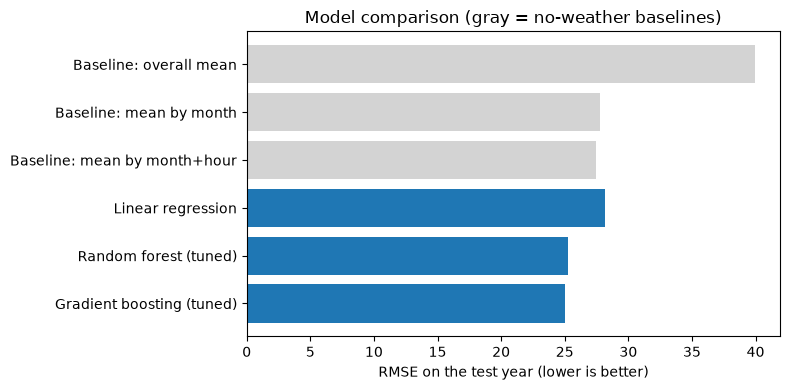

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
order = list(results.keys())
vals = [results[k]['RMSE'] for k in order]
colors = ['lightgray' if k.startswith('Baseline') else 'tab:blue' for k in order]
ax.barh(order[::-1], vals[::-1], color=colors[::-1])
ax.set_xlabel('RMSE on the test year (lower is better)'); ax.set_title('Model comparison (gray = no-weather baselines)')
plt.tight_layout(); plt.show()

Best non-baseline model on RMSE: Gradient boosting (tuned)


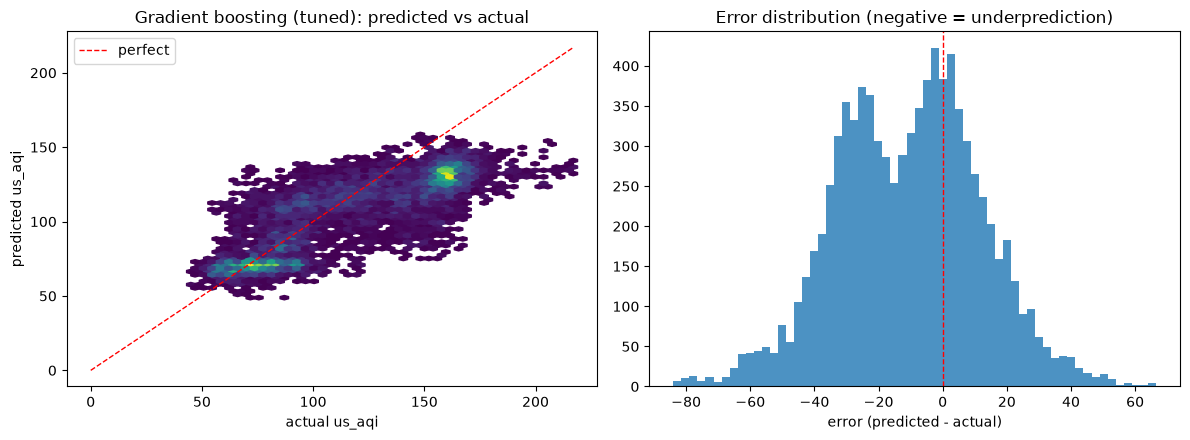

In [13]:
best_name = min([k for k in results if not k.startswith('Baseline')], key=lambda k: results[k]['RMSE'])
print('Best non-baseline model on RMSE:', best_name)
p = test_pred[best_name]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hexbin(y_test, p, gridsize=45, cmap='viridis', mincnt=1)
lims = [0, max(y_test.max(), p.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1, label='perfect')
axes[0].set_xlabel('actual us_aqi'); axes[0].set_ylabel('predicted us_aqi'); axes[0].set_title(f'{best_name}: predicted vs actual'); axes[0].legend()

res = p - y_test.values
axes[1].hist(res, bins=60, color='tab:blue', alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_xlabel('error (predicted - actual)'); axes[1].set_title('Error distribution (negative = underprediction)')
plt.tight_layout(); plt.show()

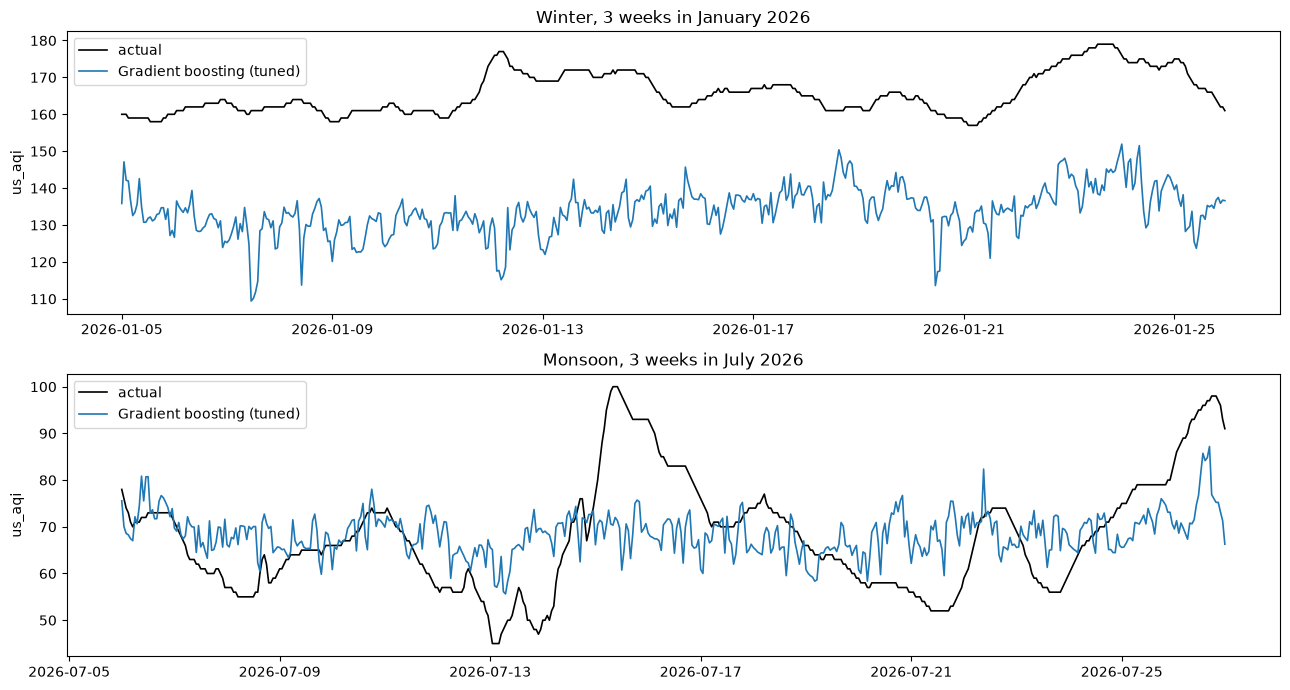

In [14]:
# a few weeks of the test year: actual versus predicted
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, (a, b, ttl) in zip(axes, [('2026-01-05', '2026-01-26', 'Winter, 3 weeks in January 2026'),
                                   ('2026-07-06', '2026-07-27', 'Monsoon, 3 weeks in July 2026')]):
    m = (test['time'] >= a) & (test['time'] < b)
    ax.plot(test.loc[m, 'time'], y_test[m], label='actual', color='black', linewidth=1.2)
    ax.plot(test.loc[m, 'time'], p[m.values], label=best_name, color='tab:blue', linewidth=1.2)
    ax.set_title(ttl); ax.set_ylabel('us_aqi'); ax.legend()
plt.tight_layout(); plt.show()

## 10. Where does it work and where does it fail?
An overall score hides a lot. Breaking the test year down by season and by real AQI band shows the pattern the report needs.
Seasons: winter (Dec-Feb), pre-monsoon (Mar-May), monsoon (Jun-Sep), post-monsoon (Oct-Nov).

In [15]:
SEASON = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Pre-monsoon', 4: 'Pre-monsoon', 5: 'Pre-monsoon',
          6: 'Monsoon', 7: 'Monsoon', 8: 'Monsoon', 9: 'Monsoon', 10: 'Post-monsoon', 11: 'Post-monsoon'}
season = test['month'].map(SEASON).reset_index(drop=True)

def breakdown(groups, pred, order):
    rows = []
    for g in order:
        m = (groups == g).values
        if m.sum() == 0:
            continue
        yt = y_test.values[m]; yp = pred[m]
        rows.append({'group': g, 'hours': int(m.sum()), 'actual mean': yt.mean(), 'predicted mean': yp.mean(),
                     'MAE': mean_absolute_error(yt, yp), 'RMSE': float(np.sqrt(mean_squared_error(yt, yp))),
                     'Bias': float(np.mean(yp - yt))})
    return pd.DataFrame(rows).set_index('group').round(1)

print('BY SEASON,', best_name)
by_season = breakdown(season, test_pred[best_name], ['Winter', 'Pre-monsoon', 'Monsoon', 'Post-monsoon'])
by_season

BY SEASON, Gradient boosting (tuned)


,hours,actual mean,predicted mean,MAE,RMSE,Bias
group,,,,,,
Winter,2160,157.4,131.7,26.2,28.3,-25.7
Pre-monsoon,2208,123.4,114.6,26.3,32.1,-8.8
Monsoon,2928,85.0,79.1,12.4,16.5,-5.9
Post-monsoon,1464,101.6,100.7,15.8,21.4,-0.9


In [16]:
print('BY SEASON, month-only baseline for comparison')
breakdown(season, test_pred['Baseline: mean by month'], ['Winter', 'Pre-monsoon', 'Monsoon', 'Post-monsoon'])

BY SEASON, month-only baseline for comparison


,hours,actual mean,predicted mean,MAE,RMSE,Bias
group,,,,,,
Winter,2160,157.4,129.9,27.6,29.3,-27.5
Pre-monsoon,2208,123.4,108.8,31.5,38.0,-14.7
Monsoon,2928,85.0,77.8,13.6,17.7,-7.2
Post-monsoon,1464,101.6,100.1,16.7,23.4,-1.5


In [17]:
print('BY REAL AQI BAND,', best_name)
real_band = band(y_test.values)
by_band = breakdown(real_band, test_pred[best_name], BAND_LABELS)
by_band

BY REAL AQI BAND, Gradient boosting (tuned)


,hours,actual mean,predicted mean,MAE,RMSE,Bias
group,,,,,,
Good,20,48.1,64.6,16.5,17.3,16.5
Moderate,3912,79.0,82.8,13.0,16.9,3.8
Sensitive,2316,125.7,115.2,16.7,21.5,-10.6
Unhealthy,2477,162.1,129.1,33.0,35.3,-33.0
Very unhealthy,35,208.7,134.3,74.3,74.8,-74.3


In [18]:
# how often does the predicted band match the real band? rows = real, columns = predicted
conf = pd.crosstab(real_band.rename('real'), band(test_pred[best_name]).rename('predicted'), dropna=False)
conf = conf.reindex(index=BAND_LABELS, columns=BAND_LABELS, fill_value=0)
conf.loc[(conf.sum(axis=1) > 0), (conf.sum(axis=0) > 0)]

predicted,Good,Moderate,Sensitive,Unhealthy
real,,,,
Good,0,20,0,0
Moderate,3,3053,856,0
Sensitive,0,349,1959,8
Unhealthy,0,84,2367,26
Very unhealthy,0,0,33,2


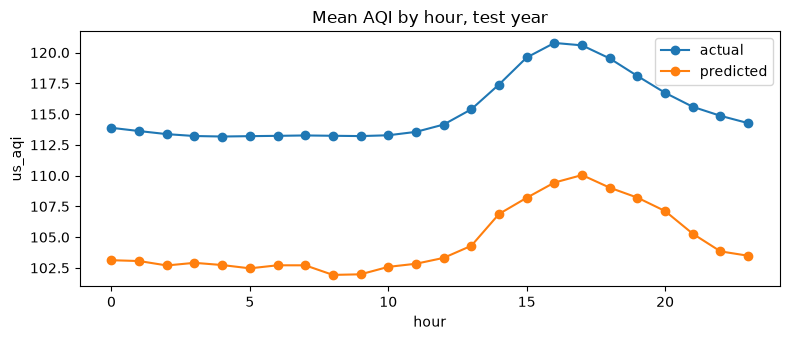

In [19]:
# by hour of day: is the evening peak captured?
hourly = pd.DataFrame({'actual': y_test.values, 'predicted': test_pred[best_name], 'hour': test['hour'].values}).groupby('hour').mean()
ax = hourly.plot(figsize=(8, 3.5), marker='o'); ax.set_title('Mean AQI by hour, test year'); ax.set_ylabel('us_aqi')
plt.tight_layout(); plt.show()

## 11. Feature importance
Permutation importance: shuffle one input on the test year and see how much the error grows. A big jump means the model leaned on that input.
Hour and month are each a sine/cosine **pair**, so each pair is shuffled together (same shuffle for both columns) and counted as one input.

random forest test RMSE: 25.3 | RMSE increase when each input is shuffled:
month (sin+cos)    14.86
dew_point_2m        5.71
hour (sin+cos)      1.11
temperature_2m      0.73
cloud_cover         0.36
precipitation      -0.07


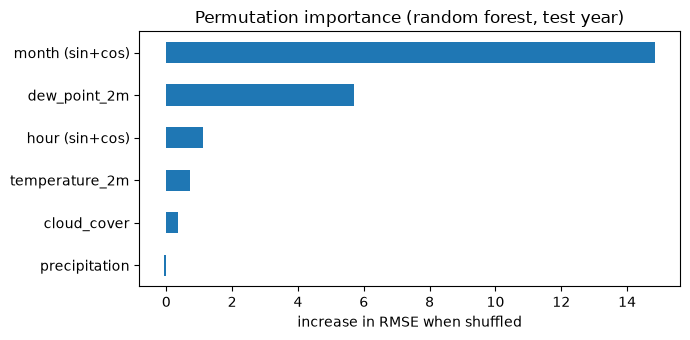

In [20]:
def grouped_permutation(model, X, y, groups, repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = np.sqrt(mean_squared_error(y, model.predict(X)))
    out = {}
    for name, cols in groups.items():
        incr = []
        for _ in range(repeats):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            Xp[cols] = X[cols].values[perm]
            incr.append(np.sqrt(mean_squared_error(y, model.predict(Xp))) - base)
        out[name] = float(np.mean(incr))
    return pd.Series(out).sort_values(ascending=False), base

GROUPS = {'dew_point_2m': ['dew_point_2m'], 'temperature_2m': ['temperature_2m'], 'cloud_cover': ['cloud_cover'],
          'precipitation': ['precipitation'], 'month (sin+cos)': ['month_sin', 'month_cos'], 'hour (sin+cos)': ['hour_sin', 'hour_cos']}

imp_rf, base_rmse = grouped_permutation(rf, X_test, y_test, GROUPS)
print('random forest test RMSE:', round(base_rmse, 2), '| RMSE increase when each input is shuffled:')
print(imp_rf.round(2).to_string())

ax = imp_rf.sort_values().plot.barh(figsize=(7, 3.5), color='tab:blue')
ax.set_xlabel('increase in RMSE when shuffled'); ax.set_title('Permutation importance (random forest, test year)')
plt.tight_layout(); plt.show()

In [21]:
# the forest's built-in importance (based on the training years), per column
pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False).round(3)

dew_point_2m      0.379
month_sin         0.254
month_cos         0.170
temperature_2m    0.072
cloud_cover       0.052
hour_sin          0.047
hour_cos          0.018
precipitation     0.009
dtype: float64

## 12. Save results

In [22]:
final_table = pd.DataFrame(results).T.round(3)
final_table.to_csv(OUT_DIR / 'model_results.csv')

preds = test[['time', TARGET]].copy()
for name, p_ in test_pred.items():
    preds[name] = p_
preds.to_csv(OUT_DIR / 'test_predictions.csv', index=False)

by_season.to_csv(OUT_DIR / 'results_by_season.csv'); by_band.to_csv(OUT_DIR / 'results_by_band.csv')
print(final_table.to_string())
print('\nSaved: model_results.csv, test_predictions.csv, results_by_season.csv, results_by_band.csv, model_*.joblib, scaler.joblib')

                                 MAE    RMSE     R2  Bias (pred - actual)  Band accuracy %
Baseline: overall mean        34.084  39.926 -0.120               -13.089           26.438
Baseline: mean by month       22.080  27.800  0.457               -13.110           56.427
Baseline: mean by month+hour  21.635  27.445  0.471               -13.110           55.902
Linear regression             22.754  28.181  0.442               -12.983           53.881
Random forest (tuned)         20.123  25.295  0.550               -10.775           57.660
Gradient boosting (tuned)     19.870  25.001  0.561               -10.681           57.511

Saved: model_results.csv, test_predictions.csv, results_by_season.csv, results_by_band.csv, model_*.joblib, scaler.joblib
